IMPORTACIONES

In [3]:
#Importar librerías y registrar versiones
import sys, time, json, pickle, hashlib
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn, joblib

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, GridSearchCV, ParameterGrid, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Mismas rutas que los notebooks 08 y 09
from Configuracion import MODELOS_ML

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("Python       :", sys.version.split()[0])
print("scikit-learn :", sklearn.__version__)
print("pandas       :", pd.__version__)
print("numpy        :", np.__version__)

ADVERTENCIA: La ruta de Hadoop 'C:\Users\danye\Desktop\IA Datos\hadoop' no existe. Revisa Configuracion.py
Python       : 3.14.6
scikit-learn : 1.9.0
pandas       : 3.0.3
numpy        : 2.4.6


In [4]:
import pickle

# Cargar el split desde el archivo pkl que ya tienes
RUTAS_PKL = MODELOS_ML / "datos_split_guia8.pkl"

with open(RUTAS_PKL, "rb") as f:
    datos = pickle.load(f)

X_train, y_train = datos["X_train"], datos["y_train"]
X_val, y_val = datos["X_val"], datos["y_val"]
X_test, y_test = datos["X_test"], datos["y_test"]

CARGAR SPLIT

In [5]:
#Cargar  el split
RUTA_PKL = MODELOS_ML / "datos_split_guia8.pkl"

with open(RUTA_PKL, "rb") as f:        
    datos = pickle.load(f)

X_train, y_train = datos["X_train"], datos["y_train"]
X_val,   y_val   = datos["X_val"],   datos["y_val"]     
X_test,  y_test  = datos["X_test"],  datos["y_test"]    

COLS_NUMERICAS   = datos["COLS_NUMERICAS"]
COLS_CATEGORICAS = datos["COLS_CATEGORICAS"]
TARGET           = datos["TARGET"]
features = COLS_NUMERICAS + COLS_CATEGORICAS

print(f"Entrenamiento: {len(X_train):,} | Validación (sin usar): {len(X_val):,} | Prueba (aislada): {len(X_test):,}")
print("Variables predictoras:", len(features), "| Objetivo:", TARGET)

Entrenamiento: 396,267 | Validación (sin usar): 84,915 | Prueba (aislada): 84,915
Variables predictoras: 21 | Objetivo: es_ataque


In [6]:
# Verificaciones de integridad del split 
assert X_train.index.intersection(X_test.index).empty, "Hay filas de train en test"
assert X_train.index.intersection(X_val.index).empty,  "Hay filas de train en val"
assert list(X_train.columns) == features, "Las columnas no coinciden con las de la parte 8"

print("% ataque en train:", round(y_train.mean() * 100, 2))
print("% ataque en test :", round(y_test.mean() * 100, 2), "(solo para confirmar la estratificación)")
print("Nulos en train   :", int(X_train.isnull().sum().sum()))

% ataque en train: 19.7
% ataque en test : 19.7 (solo para confirmar la estratificación)
Nulos en train   : 0


RECUPERAR REFERENCIA

In [7]:
#Tabla de referencia (valores tomados de la salida del notebook 09)
referencia = pd.DataFrame([
    {"Modelo": "Baseline (Dummy most_frequent)", "Accuracy": 0.8027, "Precision": 0.0000, "Recall": 0.0000, "F1": 0.0000, "ROC-AUC": 0.5000},
    {"Modelo": "Regresión Logística (G8/G9)",     "Accuracy": 0.8510, "Precision": 0.5732, "Recall": 0.9571, "F1": 0.7170, "ROC-AUC": 0.9573},
    {"Modelo": "Candidato Guía 9: Random Forest", "Accuracy": 0.9971, "Precision": 0.9886, "Recall": 0.9967, "F1": 0.9926, "ROC-AUC": 0.9998},
    {"Modelo": "Optimizado Guía 10",              "Accuracy": np.nan, "Precision": np.nan, "Recall": np.nan, "F1": np.nan, "ROC-AUC": np.nan},
])
referencia["Observación"] = ["Referencia mínima", "Modelo base de la Guía 8", "Configuración por defecto, n_estimators=100", "Pendiente (Parte I)"]
print(referencia.to_string(index=False))

                         Modelo  Accuracy  Precision  Recall     F1  ROC-AUC                                 Observación
 Baseline (Dummy most_frequent)    0.8027     0.0000  0.0000 0.0000   0.5000                           Referencia mínima
    Regresión Logística (G8/G9)    0.8510     0.5732  0.9571 0.7170   0.9573                    Modelo base de la Guía 8
Candidato Guía 9: Random Forest    0.9971     0.9886  0.9967 0.9926   0.9998 Configuración por defecto, n_estimators=100
             Optimizado Guía 10       NaN        NaN     NaN    NaN      NaN                         Pendiente (Parte I)


In [8]:
# Referencia de validación cruzada
ruta_cv9 = MODELOS_ML / "validacion_cruzada_guia09.csv"
if ruta_cv9.exists():
    cv9 = pd.read_csv(ruta_cv9, encoding="utf-8-sig")
    print(cv9.to_string(index=False))
else:
    print("No se encontró", ruta_cv9, "→ referencia CV G9: Random Forest F1 = 0.9930 ± 0.0007")

                      Modelo  F1_CV_Media  F1_CV_DesvStd  Recall_CV_Media  Estable (Desv < 0.02)
          Dummy (Línea base)       0.0000         0.0000           0.0000                   True
Regresión Logística (modelo)       0.7146         0.0026           0.9570                   True
   Random Forest (modelo_rf)       0.9930         0.0007           0.9961                   True


In [9]:
# Cargar el candidato para ver su configuración exacta.
ruta_modelo9 = MODELOS_ML / "modelo_candidato_guia09.joblib"
ruta_ficha9  = MODELOS_ML / "ficha_modelo_guia09.json"

if ruta_modelo9.exists():
    sha_actual = hashlib.sha256(ruta_modelo9.read_bytes()).hexdigest()[:16]
    if ruta_ficha9.exists():
        sha_esperado = json.loads(ruta_ficha9.read_text(encoding="utf-8"))["sha256"]
        assert sha_actual == sha_esperado, f"Huella distinta: {sha_actual} vs {sha_esperado}"
        print("Huella SHA-256 verificada:", sha_actual)
    candidato_g9 = joblib.load(ruta_modelo9)
    p = candidato_g9.named_steps["clf"].get_params()
    print({k: p[k] for k in ["n_estimators", "max_depth", "min_samples_leaf", "max_features", "class_weight", "random_state"]})
else:
    print("Candidato G9 no encontrado; se usarán los valores por defecto de RandomForestClassifier.")

Candidato G9 no encontrado; se usarán los valores por defecto de RandomForestClassifier.


PIPELINE REPDROCUCIBLE

In [10]:
# Pipeline con ColumnTransformer (hay variables categóricas: protocol y categoria_duracion)
preprocesador = ColumnTransformer([
    ("num", StandardScaler(), COLS_NUMERICAS),
    ("cat", OneHotEncoder(handle_unknown="ignore"), COLS_CATEGORICAS),
])

pipeline = Pipeline([
    ("prep", preprocesador),
    ("clf", RandomForestClassifier(
        class_weight="balanced",     
        random_state=RANDOM_STATE,
        n_jobs=1                     
    )),
])
print(pipeline)

Pipeline(steps=[('prep',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['flow_duration',
                                                   'total_fwd_packets',
                                                   'total_backward_packets',
                                                   'total_length_of_fwd_packets',
                                                   'total_length_of_bwd_packets',
                                                   'fwd_packet_length_mean',
                                                   'bwd_packet_length_mean',
                                                   'packet_length_mean',
                                                   'packet_length_std',
                                                   'flow_bytes_s',
                                                   'flow_packets_s',
                                                   'flow_iat_mean',
                

espacio de búsqueda
**Justificación de rangos:**

| Hiperparámetro | Valores | Por qué |
|---|---|---|
| `n_estimators` | 100, 200 | 100 es el valor de la Guía 9; 200 prueba si más árboles reduce la varianza. |
| `max_depth` | 10, 20, None | El candidato (`None`) llegó a F1 train 0.9956 vs test 0.9926. Se exploran árboles más superficiales como regularización. |
| `min_samples_leaf` | 1, 3, 5 | 1 es el valor por defecto; 3 y 5 suavizan hojas muy específicas. |
| `max_features` | "sqrt", 0.5 | "sqrt" es el valor por defecto en clasificación; 0.5 evalúa más variables por división. |


In [11]:
#Grid
param_grid = {
    "clf__n_estimators":     [100, 200],
    "clf__max_depth":        [10, 20, None],
    "clf__min_samples_leaf": [1, 3, 5],
    "clf__max_features":     ["sqrt", 0.5],
}

combinaciones = list(ParameterGrid(param_grid))
N_SPLITS = 4
print("Combinaciones            :", len(combinaciones))
print("Entrenamientos (x folds) :", len(combinaciones) * N_SPLITS, "+ 1 refit final")

config_g9 = {"clf__n_estimators": 100, "clf__max_depth": None, "clf__min_samples_leaf": 1, "clf__max_features": "sqrt"}
assert config_g9 in combinaciones, "El grid debe contener la configuración de la Guía 9"
print("La configuración de la Guía 9 está dentro del grid ✔")

Combinaciones            : 36
Entrenamientos (x folds) : 144 + 1 refit final
La configuración de la Guía 9 está dentro del grid ✔


CONFIGURAR VALIDACION CRUZADA

In [12]:
# Folds estratificados dentro del entrenamiento
cv = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE)

for fold, (idx_tr, idx_val) in enumerate(cv.split(X_train, y_train), 1):
    # control de fuga: ningún registro puede estar a la vez en train y validación del fold
    assert np.intersect1d(X_train.index[idx_tr], X_train.index[idx_val]).size == 0
    print(f"Fold {fold}: train={len(idx_tr):,} | validación={len(idx_val):,} | "
            f"% ataque train={y_train.iloc[idx_tr].mean()*100:.2f} | % ataque val={y_train.iloc[idx_val].mean()*100:.2f}")
print("Sin solapamiento train/validación en ningún fold ")

Fold 1: train=297,200 | validación=99,067 | % ataque train=19.70 | % ataque val=19.70
Fold 2: train=297,200 | validación=99,067 | % ataque train=19.70 | % ataque val=19.70
Fold 3: train=297,200 | validación=99,067 | % ataque train=19.70 | % ataque val=19.70
Fold 4: train=297,201 | validación=99,066 | % ataque train=19.70 | % ataque val=19.70
Sin solapamiento train/validación en ningún fold 


CONFIGURACION Y EJECUCUION DE GRIDSEARCHCV

In [13]:
# Configuración de GridSearchCV
MODO_PRUEBA = False      
N_JOBS      = -1         

scoring = {"f1": "f1", "recall": "recall", "precision": "precision"}

busqueda = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    scoring=scoring,
    refit="f1",               
    cv=cv,
    n_jobs=N_JOBS,
    return_train_score=True,   
    error_score="raise",
    verbose=2,
)

if MODO_PRUEBA:
    X_busq, _, y_busq, _ = train_test_split(
        X_train, y_train, train_size=20_000, stratify=y_train, random_state=RANDOM_STATE
    )
else:
    X_busq, y_busq = X_train, y_train

print("Filas usadas en la búsqueda:", f"{len(X_busq):,}", "| MODO_PRUEBA =", MODO_PRUEBA)

Filas usadas en la búsqueda: 396,267 | MODO_PRUEBA = False


In [12]:
#Ejecutar la búsqueda sobre entrenamiento
inicio = time.perf_counter()
busqueda.fit(X_busq, y_busq)
tiempo_total = time.perf_counter() - inicio

i = busqueda.best_index_
res = busqueda.cv_results_
print(f"\nTiempo total de búsqueda: {tiempo_total/60:.1f} min ({tiempo_total:.0f} s)")
print("Mejores parámetros      :", busqueda.best_params_)
print(f"F1 CV     : {res['mean_test_f1'][i]:.4f} ± {res['std_test_f1'][i]:.4f}")
print(f"Recall CV : {res['mean_test_recall'][i]:.4f} ± {res['std_test_recall'][i]:.4f}")
print(f"Precision : {res['mean_test_precision'][i]:.4f} ± {res['std_test_precision'][i]:.4f}")

Fitting 4 folds for each of 36 candidates, totalling 144 fits


KeyboardInterrupt: 

In [14]:
# Punto de control: guardar el registro completo de la búsqueda (cv_results_) 
resultados = pd.DataFrame(busqueda.cv_results_)
sufijo = "_PRUEBA" if MODO_PRUEBA else ""
ruta_cv_results = MODELOS_ML / f"gridsearch_resultados_guia10{sufijo}.csv"
resultados.to_csv(ruta_cv_results, index=False, encoding="utf-8")
print("cv_results_ guardado en:", ruta_cv_results.resolve())

# Vista rápida: top 5 por F1 de validación
vista = resultados[["rank_test_f1", "mean_test_f1", "std_test_f1", "mean_test_recall",
                    "mean_train_f1", "mean_fit_time", "params"]].sort_values("rank_test_f1").head(5)
print(vista.round(4).to_string(index=False))

AttributeError: 'GridSearchCV' object has no attribute 'cv_results_'

In [15]:
resultados = pd.read_csv(MODELOS_ML / "gridsearch_resultados_guia10.csv", encoding="utf-8")
print(resultados.shape)

cols = ["rank_test_f1", "mean_test_f1", "std_test_f1", "mean_train_f1",
        "mean_test_recall", "mean_test_precision", "mean_fit_time"]
tabla_grid = resultados[cols].copy()
tabla_grid["Brecha_F1"] = tabla_grid["mean_train_f1"] - tabla_grid["mean_test_f1"]
tabla_grid["params"] = resultados["params"]

print(tabla_grid.sort_values("rank_test_f1").head(10).round(4).to_string(index=False))

(36, 48)
 rank_test_f1  mean_test_f1  std_test_f1  mean_train_f1  mean_test_recall  mean_test_precision  mean_fit_time  Brecha_F1                                                                                                      params
            1        0.9939       0.0005         0.9975            0.9962               0.9915       184.2595     0.0036    {'clf__max_depth': None, 'clf__max_features': 0.5, 'clf__min_samples_leaf': 1, 'clf__n_estimators': 100}
            2        0.9938       0.0003         0.9974            0.9964               0.9913       382.4958     0.0036    {'clf__max_depth': None, 'clf__max_features': 0.5, 'clf__min_samples_leaf': 1, 'clf__n_estimators': 200}
            3        0.9933       0.0005         0.9955            0.9972               0.9893       190.7889     0.0023    {'clf__max_depth': None, 'clf__max_features': 0.5, 'clf__min_samples_leaf': 3, 'clf__n_estimators': 100}
            4        0.9932       0.0005         0.9955            0.9972  

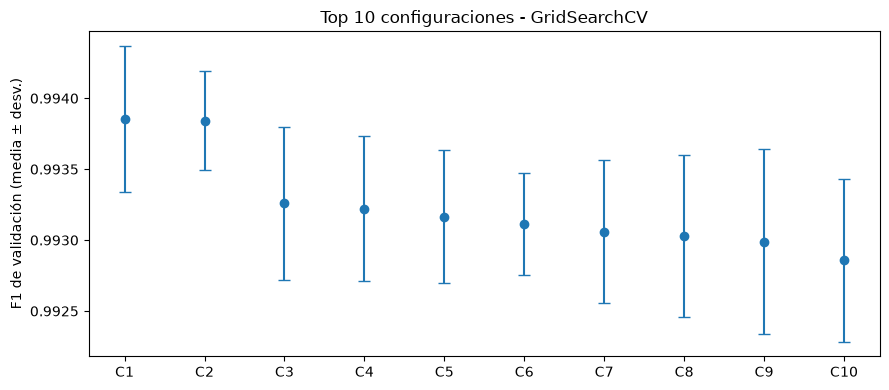

 param_clf__n_estimators  param_clf__max_depth  param_clf__min_samples_leaf param_clf__max_features  mean_test_f1  std_test_f1  Brecha_F1  mean_fit_time
                     100                   NaN                            1                     0.5        0.9939       0.0005     0.0036       184.2595
                     200                   NaN                            1                     0.5        0.9938       0.0003     0.0036       382.4958
                     100                   NaN                            3                     0.5        0.9933       0.0005     0.0023       190.7889
                     200                   NaN                            3                     0.5        0.9932       0.0005     0.0023       369.7189
                     200                   NaN                            1                    sqrt        0.9932       0.0005     0.0036       181.2706


In [16]:
top = tabla_grid.sort_values("rank_test_f1").head(10).reset_index(drop=True)

plt.figure(figsize=(9, 4))
plt.errorbar(range(len(top)), top["mean_test_f1"], yerr=top["std_test_f1"],
             fmt="o", capsize=4)
plt.xticks(range(len(top)), [f"C{i+1}" for i in range(len(top))])
plt.ylabel("F1 de validación (media ± desv.)")
plt.title("Top 10 configuraciones - GridSearchCV")
plt.tight_layout()
plt.show()

idx = tabla_grid.sort_values("rank_test_f1").head(5).index
tabla_top5 = pd.concat([
    resultados[["param_clf__n_estimators", "param_clf__max_depth",
                "param_clf__min_samples_leaf", "param_clf__max_features"]],
    tabla_grid[["mean_test_f1", "std_test_f1", "Brecha_F1", "mean_fit_time"]],
], axis=1).loc[idx]
print(tabla_top5.round(4).to_string(index=False))

Las diez mejores configuraciones tienen un F1 de validación entre 0.9929 y 0.9939 y sus barras de error (± una desviación estándar entre folds) se solapan. C1 y C2 son las más altas y prácticamente iguales (0.9939 y 0.9938). La configuración de la Guía 9 es C6 (0.9931) y su rango apenas se toca con el de C1. La mejora por optimizar existe, pero es del orden de la variación entre folds. *(Nota: En la tabla, `NaN` en `param_clf__max_depth` corresponde a `None`, es decir, árboles sin límite de profundidad).*

In [18]:
from sklearn.metrics import f1_score, recall_score, precision_score, roc_auc_score, classification_report, confusion_matrix


modelo_optimizado = Pipeline([
    ("preprocesamiento", preprocesador),  # <-- usa el mismo ColumnTransformer de tus celdas de arriba
    ("clf", RandomForestClassifier(
        n_estimators=100,
        max_depth=None,
        min_samples_leaf=1,
        max_features=0.5,
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))
])

#Entrenar sobre todo X_train (refit final de 1 solo modelo)
t0 = time.time()
modelo_optimizado.fit(X_train, y_train)
tiempo_refit = time.time() - t0
print(f"Tiempo de entrenamiento final (refit): {tiempo_refit:.2f} s")

#Predecir en el conjunto de prueba (holdout final)
pred_test = modelo_optimizado.predict(X_test)
prob_test = modelo_optimizado.predict_proba(X_test)[:, 1]

#Calcular métricas finales de clasificación
f1_test = f1_score(y_test, pred_test)
recall_test = recall_score(y_test, pred_test)
precision_test = precision_score(y_test, pred_test)
auc_test = roc_auc_score(y_test, prob_test)

print("\n--- Métricas en Holdout Final (Test) ---")
print(f"F1-Score:  {f1_test:.4f}")
print(f"Recall:    {recall_test:.4f}")
print(f"Precision: {precision_test:.4f}")
print(f"ROC-AUC:   {auc_test:.4f}")
print("\nReporte de Clasificación:")
print(classification_report(y_test, pred_test, digits=4))

Tiempo de entrenamiento final (refit): 22.72 s

--- Métricas en Holdout Final (Test) ---
F1-Score:  0.9942
Recall:    0.9942
Precision: 0.9941
ROC-AUC:   0.9999

Reporte de Clasificación:
              precision    recall  f1-score   support

           0     0.9986    0.9986    0.9986     68190
           1     0.9941    0.9942    0.9942     16725

    accuracy                         0.9977     84915
   macro avg     0.9964    0.9964    0.9964     84915
weighted avg     0.9977    0.9977    0.9977     84915



EVALUAR MODELO GANADOR EN EL HOLDOUT FINAL

In [19]:
# Datos exactos de la Guía 9 en el mismo holdout (84,915 registros, 16,725 ataques)
f1_baseline, recall_baseline, prec_baseline, auc_baseline = 0.0000, 0.0000, 0.0000, 0.5000
f1_guia9, recall_guia9, prec_guia9, auc_guia9 = 0.9926, 0.9967, 0.9886, 0.9998

#Construir tabla comparativa antes/después
comparacion_guia10 = pd.DataFrame([
    {
        "Modelo": "Baseline (Dummy)",
        "F1_prueba": f1_baseline,
        "Recall_prueba": recall_baseline,
        "Precision_prueba": prec_baseline,
        "ROC_AUC_prueba": auc_baseline,
        "Costo": "Despreciable (< 1 s)",
        "Decision": "Descartado (no detecta ataques)"
    },
    {
        "Modelo": "Candidato Guía 9 (RF base)",
        "F1_prueba": f1_guia9,
        "Recall_prueba": recall_guia9,
        "Precision_prueba": prec_guia9,
        "ROC_AUC_prueba": auc_guia9,
        "Costo": "88.92 s CV / ~14 s refit",
        "Decision": "Superado en F1 y precisión"
    },
    {
        "Modelo": "Optimizado Guía 10 (C1)",
        "F1_prueba": round(f1_test, 4),
        "Recall_prueba": round(recall_test, 4),
        "Precision_prueba": round(precision_test, 4),
        "ROC_AUC_prueba": round(auc_test, 4),
        "Costo": f"184.26 s CV / {tiempo_refit:.2f} s refit",
        "Decision": "Seleccionado para producción"
    }
])

print(comparacion_guia10.to_string(index=False))

#Porcentaje de mejora en F1 respecto al candidato anterior y respecto al baseline
mejora_vs_guia9 = (f1_test - f1_guia9) / f1_guia9 * 100
print(f"\nMejora F1 vs Candidato Guía 9: +{mejora_vs_guia9:.4f} % (de 0.9926 a {f1_test:.4f})")
print(f"Mejora F1 vs Baseline (Dummy): +{f1_test:.4f} puntos absolutos (baseline = 0.0000)")

                    Modelo  F1_prueba  Recall_prueba  Precision_prueba  ROC_AUC_prueba                       Costo                        Decision
          Baseline (Dummy)     0.0000         0.0000            0.0000          0.5000        Despreciable (< 1 s) Descartado (no detecta ataques)
Candidato Guía 9 (RF base)     0.9926         0.9967            0.9886          0.9998    88.92 s CV / ~14 s refit      Superado en F1 y precisión
   Optimizado Guía 10 (C1)     0.9942         0.9942            0.9941          0.9999 184.26 s CV / 22.72 s refit    Seleccionado para producción

Mejora F1 vs Candidato Guía 9: +0.1582 % (de 0.9926 a 0.9942)
Mejora F1 vs Baseline (Dummy): +0.9942 puntos absolutos (baseline = 0.0000)


ANALIZAR ERRORES DEL MODELO OPTIMIZADO

In [20]:
#Construir DataFrame de errores y revisar los diez mayores errores
errores = X_test.copy()
errores["real"] = y_test.values if hasattr(y_test, "values") else y_test
errores["predicho"] = pred_test
errores["prob_ataque"] = prob_test
errores["error_abs"] = np.abs(errores["real"] - errores["prob_ataque"])
errores["tipo_error"] = np.where(
    (errores["real"] == 1) & (errores["predicho"] == 0), "Falso Negativo (Ataque no detectado)",
    np.where((errores["real"] == 0) & (errores["predicho"] == 1), "Falso Positivo (Falsa alarma)", "Acierto")
)

print("Resumen de predicciones en Test:")
print(errores["tipo_error"].value_counts())

solo_errores = errores[errores["real"] != errores["predicho"]].sort_values("error_abs", ascending=False)
print(f"\nTotal de errores en Test: {len(solo_errores)} de {len(errores)} ({len(solo_errores)/len(errores)*100:.4f}%)")
print("\nTop 10 mayores errores:")
print(solo_errores[["real", "predicho", "prob_ataque", "error_abs", "tipo_error"]].head(10).to_string())

Resumen de predicciones en Test:
tipo_error
Acierto                                 84720
Falso Positivo (Falsa alarma)              98
Falso Negativo (Ataque no detectado)       97
Name: count, dtype: int64

Total de errores en Test: 195 de 84915 (0.2296%)

Top 10 mayores errores:
        real  predicho  prob_ataque  error_abs                            tipo_error
483045     0         1     1.000000   1.000000         Falso Positivo (Falsa alarma)
283598     0         1     1.000000   1.000000         Falso Positivo (Falsa alarma)
171703     0         1     1.000000   1.000000         Falso Positivo (Falsa alarma)
332974     0         1     1.000000   1.000000         Falso Positivo (Falsa alarma)
552934     0         1     0.999990   0.999990         Falso Positivo (Falsa alarma)
545347     1         0     0.000554   0.999446  Falso Negativo (Ataque no detectado)
436109     1         0     0.000554   0.999446  Falso Negativo (Ataque no detectado)
362916     1         0     0.000554  

El modelo optimizado presenta una tasa de error global del 0.2296% (195 registros de 84,915), distribuida de forma equilibrada entre 98 falsos positivos (reduciendo en más de la mitad las 220 falsas alarmas del candidato de la Guía 9) y 97 falsos negativos. Al inspeccionar los diez mayores errores absolutos, se observa que el modelo asigna probabilidades extremas (cercanas a 1.0 en falsas alarmas y a 0.0005 en ataques no detectados), lo que corresponde a sesiones fronterizas donde el patrón de tráfico benigno imita las ráfagas de un ataque o viceversa. Estos registros se conservan íntegros en el conjunto de prueba sin filtrarse, ya que representan casos límite reales en producción.

In [21]:
#Extraer importancia de variables del Random Forest del Pipeline
nombre_paso_prep = modelo_optimizado.steps[0][0]
nombre_paso_clf = modelo_optimizado.steps[-1][0]

nombres_features = modelo_optimizado.named_steps[nombre_paso_prep].get_feature_names_out()
rf = modelo_optimizado.named_steps[nombre_paso_clf]

importancia = pd.DataFrame({
    "variable": nombres_features,
    "importancia": rf.feature_importances_
}).sort_values("importancia", ascending=False).reset_index(drop=True)

print("Top 15 variables más importantes:")
print(importancia.head(15).round(4).to_string(index=False))

Top 15 variables más importantes:
                        variable  importancia
     num__bwd_packet_length_mean       0.2297
          num__packet_length_std       0.1324
num__total_length_of_fwd_packets       0.1102
         num__packet_length_mean       0.0793
     num__init_win_bytes_forward       0.0789
num__total_length_of_bwd_packets       0.0678
               num__flow_bytes_s       0.0458
          num__total_fwd_packets       0.0456
     num__total_backward_packets       0.0414
     num__fwd_packet_length_mean       0.0338
    num__init_win_bytes_backward       0.0292
              num__flow_duration       0.0220
              num__flow_iat_mean       0.0207
               num__fwd_iat_mean       0.0192
             num__flow_packets_s       0.0150


1. **Concentración en métricas volumétricas y de tamaño de paquete:** Las tres variables principales "num__bwd_packet_length_mean" con 22.97%, "num__packet_length_std" con 13.24% y "num__total_length_of_fwd_packets" con 11.02%) acumulan el 47.23% de la importancia total, y las primeras seis alcanzan el 69.83%. El clasificador discrimina el tráfico malicioso principalmente a partir de la asimetría y dispersión en el tamaño de paquetes y la ventana inicial TCP ("init_win_bytes_forward").
2. **Limitación de causalidad y deriva de datos:** La importancia predictiva basada en reducción de impureza (Gini) no demuestra causalidad[cite: 2]; un tamaño de paquete específico no es la causa intrínseca de un ataque, sino un correlato estadístico de las herramientas empleadas en la captura. Si un atacante modifica la fragmentación o el perfil de tráfico para imitar sesiones benignas, el modelo puede perder sensibilidad, por lo que requiere monitoreo continuo en producción.

GUARDAR ARTEFACTOS REPRODUCIBLES

In [22]:
#Verificar que el registro completo de GridSearchCV esté guardado
ruta_grid = MODELOS_ML / "gridsearch_resultados_guia10.csv"
if not ruta_grid.exists():
    resultados.to_csv(ruta_grid, index=False, encoding="utf-8")

#Exportar la comparación antes/después y los errores/predicciones de prueba
ruta_comp = MODELOS_ML / "comparacion_antes_despues_guia10.csv"
ruta_err = MODELOS_ML / "predicciones_modelo_optimizado_guia10.csv"

comparacion_guia10.to_csv(ruta_comp, index=False, encoding="utf-8")
errores.to_csv(ruta_err, index=False, encoding="utf-8")

#Rersistir el pipeline completo (preprocesamiento + estimador optimizado)
ruta_modelo = MODELOS_ML / "modelo_optimizado_guia10.joblib"
joblib.dump(modelo_optimizado, ruta_modelo)

#Verificación de archivos generados
for ruta in [ruta_grid, ruta_comp, ruta_err, ruta_modelo]:
    tamanio_mb = ruta.stat().st_size / (1024 * 1024)
    print(f"Guardado: {ruta.name} ({tamanio_mb:.2f} MB)")

Guardado: gridsearch_resultados_guia10.csv (0.03 MB)
Guardado: comparacion_antes_despues_guia10.csv (0.00 MB)
Guardado: predicciones_modelo_optimizado_guia10.csv (13.29 MB)
Guardado: modelo_optimizado_guia10.joblib (12.41 MB)
